In [1]:
from binance.client import Client as bnb_client
import datetime
import pandas as pd 
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import math

# 0. Download the data

In [2]:
tickers = [ "BTC-USD", "ETH-USD", "BNB-USD", "XRP-USD", "SOL-USD", "TRX-USD", "ZEC-USD", "DOGE-USD", "XMR-USD", "LINK-USD", "LEO-USD", "ADA-USD", "NEAR-USD", "XLM-USD", "BCH-USD", "DEL-USD", "LTC-USD", "UNI7083-USD", "AVAX-USD", "HBAR-USD", "CRO-USD", "OKB-USD", "QNT-USD", "AAVE-USD", "DOT-USD", "ICP-USD", "BGB-USD", "ETC-USD", "JST-USD", "GT-USD", "KCS-USD", "ALGO-USD", "RENDER-USD", "ATOM-USD", "FIL-USD", "INJ-USD", "XDC-USD", "CAKE-USD", "STX4847-USD", "DASH-USD", ]

data = yf.download(tickers, period='6y', interval='1d', group_by='ticker')

[*********************100%***********************]  40 of 40 completed


In [3]:
data.to_csv('crypto_raw_data.csv')

In [4]:
COST_PER_TRANSACTION = 20/10000

In [5]:
def calculate_performance(df, freq='daily'):
    ANNUAL_DAYS = 365
    
    res = {}
    res['avg_return'] = float(df.sum(axis=1).mean())
    res['std'] = float(df.sum(axis=1).std())
    if freq == 'daily':
        res['avg_return'] = res['avg_return'] * ANNUAL_DAYS
        res['std'] = res['std'] * math.sqrt(ANNUAL_DAYS)
    res['sharpe_ratio'] = float(res['avg_return'] / res['std'])

    return res

In [6]:
def compute_moving_average(close, days=50):
    ma = close.rolling(days).mean()
    return ma

In [7]:
def drawdown(daily_ret):
    cum = daily_ret.cumsum()
    peak = cum.cummax().clip(lower=0)
    return cum-peak

def drawdown_duration(dd):
    in_dd = dd < 0
    return in_dd.groupby((~in_dd).cumsum()).cumsum()
    
def drawdown_compounded(daily_ret):
    equity = (1 + daily_ret).cumprod()
    peak = equity.cummax().clip(lower=1)  # start (1.0) counts as a peak
    return equity / peak - 1

In [8]:
def calculate_performance_daily_return(df):
    res = {}
    res['avg_return'] = float(df.mean()) * 252
    res['std'] = float(df.std()) * math.sqrt(252)
    res['sharpe_ratio'] = float(res['avg_return'] / res['std'])

    return res

# 1. Momentum for Crypto

## 1a. Limited cash (Only buy if we don't have position on that coin and close > moving average of close price)

In [9]:
close = data.xs('Close', axis=1, level=1)
close = close.iloc[:-1]
ret = (close / close.shift()) - 1

In [10]:
days = 50
ma = compute_moving_average(close, days)
ma = ma[days-1:]
close = close.loc[close.index.isin(ma.index)]
ret = ret.loc[ret.index.isin(ma.index)]

In [11]:
def run_backtest(cost, ret, close, ma):
    cash = 1
    holdings = pd.Series(0, index=close.columns)
    in_position = pd.Series(False, index=close.columns)
    entry = {}
    equity, trades = {}, []

    for day in close.index: 
        holdings = holdings * (1 + ret.loc[day].fillna(0))
        total = cash + holdings.sum()
        price, avg = close.loc[day], ma.loc[day]
        has_signal = price.notna() & avg.notna()
        n_slots = int(has_signal.sum())

        # SELL if the coin's close price fell below MA
        for coin in close.columns[in_position & has_signal & (price < avg)]:
            cash += holdings[coin] * (1 - cost)
            d0, p0 = entry.pop(coin)
            trades.append({'coin': coin, 'buy_date':d0, 'sell_date':day, 'days_held': (day-d0).days,
                          'return_after_cost': price[coin] / p0 * (1 - cost) / (1 + cost) - 1})
            holdings[coin] = 0
            in_position[coin] = False

        # BUY if we don't have position on that coin and close > moving average
        for coin in close.columns[~in_position & has_signal & (price > avg)]:
            size = min(total / n_slots, cash / (1+cost))
            if size <= 0:
                continue
            cash -= size * (1 + cost)
            holdings[coin] = size
            in_position[coin] = True
            entry[coin] = (day, price[coin])

        if n_slots > 0:
            equity[day] = cash + holdings.sum()
    
    return pd.Series(equity), pd.DataFrame(trades)

equity_after, mom_trades_after = run_backtest(COST_PER_TRANSACTION, ret, close, ma)
equity_before, _ = run_backtest(0, ret, close, ma)

### Splitting the Dataset into Train and Test Data

In [12]:
# Split equity_after, mom_trades_after, and equity_before to have train and test

half_after, half_before = len(equity_after)//2, len(equity_before)//2

train_equity_after, test_equity_after = equity_after.iloc[:half_after], equity_after.iloc[half_after:]
test_equity_after = test_equity_after/test_equity_after.iloc[0]

train_equity_before, test_equity_before = equity_before.iloc[:half_before], equity_before.iloc[half_before:]
test_equity_before = test_equity_before/test_equity_before.iloc[0]

In [13]:
train_start_date = train_equity_after.index[0]
test_start_date = test_equity_after.index[0]

train_mom_trades_after = mom_trades_after[(mom_trades_after['buy_date'] >= train_start_date) & (mom_trades_after['buy_date'] < test_start_date)].reset_index(drop=True)
test_mom_trades_after = mom_trades_after[(mom_trades_after['buy_date'] >= test_start_date)].reset_index(drop=True)

### Performance Calculation

In [14]:
train_mom_ret = train_equity_before.pct_change().dropna()
train_mom_ret_after_tx_cost = train_equity_after.pct_change().dropna()

test_mom_ret = test_equity_before.pct_change().dropna()
test_mom_ret_after_tx_cost = test_equity_after.pct_change().dropna()


In [15]:
train_mom_returns = pd.DataFrame({'before_cost': train_mom_ret, 'after_cost': train_mom_ret_after_tx_cost})

test_mom_returns = pd.DataFrame({'before_cost': test_mom_ret, 'after_cost': test_mom_ret_after_tx_cost})

### Performance Calculation

#### Return, Volatility, Sharpe Ratio

In [16]:
print('momentum performance : ')
calculate_performance_daily_return(test_mom_returns['after_cost'])


momentum performance : 


{'avg_return': 0.2790495633923254,
 'std': 0.3253213141571411,
 'sharpe_ratio': 0.8577660031753563}

#### Benchmark Return, Volatility, Sharpe Ratio

In [17]:
test_period_benchmark = ret[ret.index.isin(test_mom_returns.index)]['BTC-USD']

In [18]:
print('benchmark performance : ')
print(calculate_performance_daily_return(test_period_benchmark))

benchmark performance : 
{'avg_return': 0.26521248115029183, 'std': 0.39055900044544056, 'sharpe_ratio': 0.6790586847257688}


#### Drawdown

In [19]:
train_mom_dd = train_mom_returns.apply(drawdown_compounded)
test_mom_dd = test_mom_returns.apply(drawdown_compounded)


train_mom_dd_table = pd.DataFrame({
    'max_drawdown': train_mom_dd.min(),
    'trough_date': train_mom_dd.idxmin().dt.date,
    'longest_drawdown_days': train_mom_dd.apply(drawdown_duration).max()
})

test_mom_dd_table = pd.DataFrame({
    'max_drawdown': train_mom_dd.min(),
    'trough_date': train_mom_dd.idxmin().dt.date,
    'longest_drawdown_days': train_mom_dd.apply(drawdown_duration).max()
})

In [20]:
print('trades:', len(test_mom_trades_after))
print('median days held:', test_mom_trades_after['days_held'].median())
print('win rate:', f"{test_mom_trades_after['return_after_cost'].mean():+.1%}")
print('avg return per trade: ', f"{test_mom_trades_after['return_after_cost'].mean():+.1%}")
print('final value of $1:', round(test_equity_after.iloc[-1], 2), '(after costs)')

trades: 1399
median days held: 4.0
win rate: +2.8%
avg return per trade:  +2.8%
final value of $1: 2.61 (after costs)


### Charts

#### Daily Returns (test)

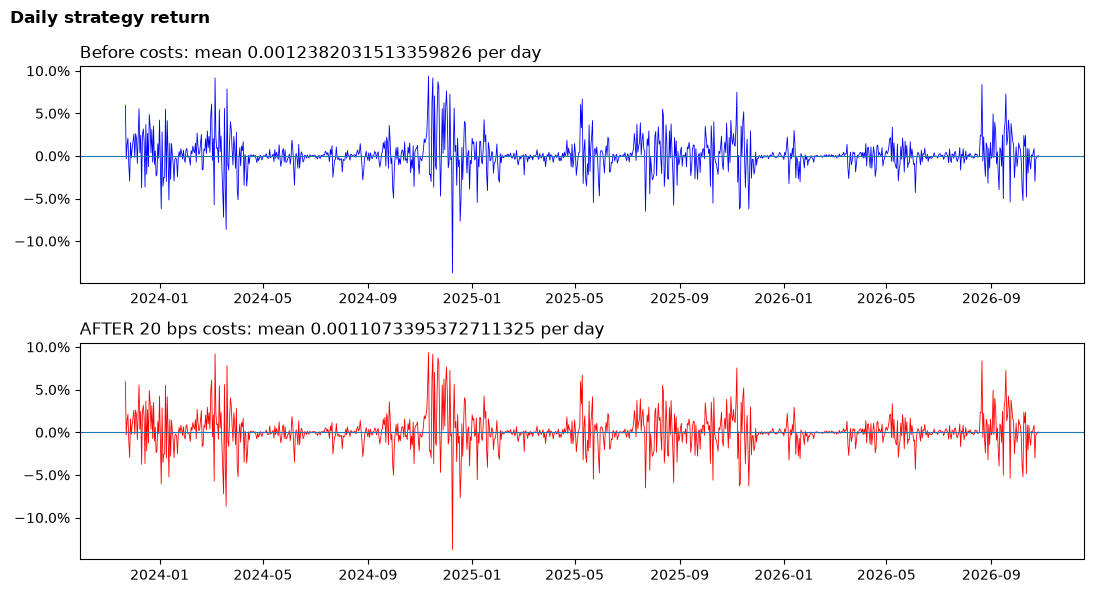

In [21]:
BLUE = 'b'
RED = 'r'

fig, axes = plt.subplots(2, 1, figsize=(11, 6))
for ax, col, color, label in [(axes[0], 'before_cost', BLUE, 'Before costs'),
                              (axes[1], 'after_cost', RED, 'AFTER 20 bps costs')]:
    ax.plot(test_mom_returns.index, test_mom_returns[col], color=color, linewidth=0.6)
    ax.axhline(0, linewidth=0.8)
    ax.set_title(f'{label}: mean {test_mom_returns[col].mean()} per day', loc='left')
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
fig.suptitle('Daily strategy return', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
plt.show()

#### Cumulative return (train)

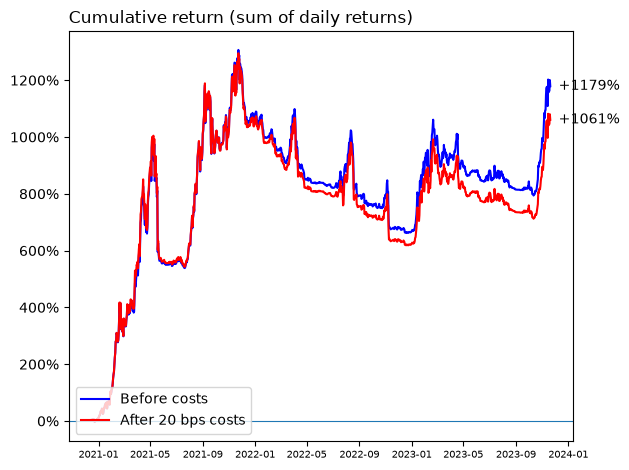

In [22]:
cum = (1 + train_mom_returns).cumprod() - 1
fig, ax = plt.subplots()
ax.plot(cum.index, cum['before_cost'], color=BLUE, label='Before costs')
ax.plot(cum.index, cum['after_cost'], color=RED, label='After 20 bps costs')
ax.axhline(0, linewidth=0.8)
for col, color in [('before_cost', BLUE), ('after_cost', RED)]:
    ax.annotate(f'{cum[col].iloc[-1]:+.0%}', (cum.index[-1], cum[col].iloc[-1]),
                xytext=(6, 0), textcoords='offset points', va='center', fontsize=10)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title('Cumulative return (sum of daily returns)', loc='left')
ax.legend(loc='lower left')
plt.xticks(fontsize=7)
fig.tight_layout()
plt.show()

#### Cumulative return (test)

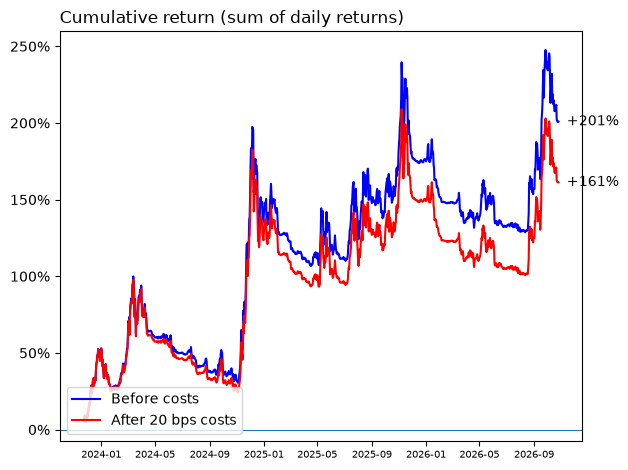

In [23]:
cum = (1 + test_mom_returns).cumprod() - 1
fig, ax = plt.subplots()
ax.plot(cum.index, cum['before_cost'], color=BLUE, label='Before costs')
ax.plot(cum.index, cum['after_cost'], color=RED, label='After 20 bps costs')
ax.axhline(0, linewidth=0.8)
for col, color in [('before_cost', BLUE), ('after_cost', RED)]:
    ax.annotate(f'{cum[col].iloc[-1]:+.0%}', (cum.index[-1], cum[col].iloc[-1]),
                xytext=(6, 0), textcoords='offset points', va='center', fontsize=10)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title('Cumulative return (sum of daily returns)', loc='left')
ax.legend(loc='lower left')
plt.xticks(fontsize=7)
fig.tight_layout()
plt.show()

#### Drawdown, before, and after costs (train)

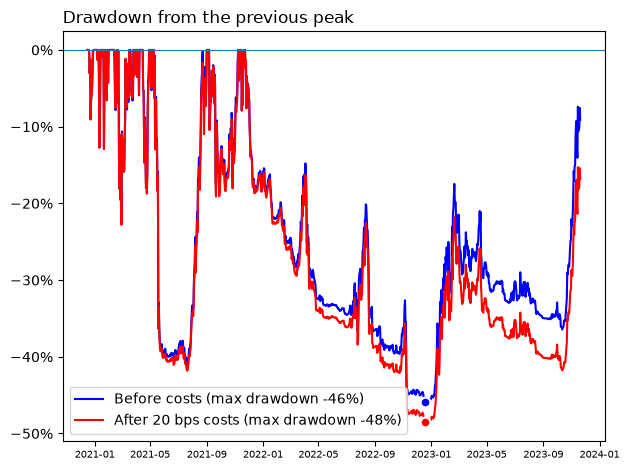

In [24]:
fig, ax = plt.subplots()
for col, color, label in [('before_cost', BLUE, 'Before costs'), ('after_cost', RED, 'After 20 bps costs')]:
    ax.plot(train_mom_dd.index, train_mom_dd[col], color=color, label=f'{label} (max drawdown {train_mom_dd[col].min():.0%})')
    ax.plot(train_mom_dd[col].idxmin(), train_mom_dd[col].min(), 'o', color=color, markersize=7,
            markeredgecolor='white', markeredgewidth=1.5)
ax.axhline(0, linewidth=0.8)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title('Drawdown from the previous peak', loc='left')
ax.legend(loc='lower left')
plt.xticks(fontsize=7)
fig.tight_layout()
plt.show()

#### Drawdown, before, and after costs (test)

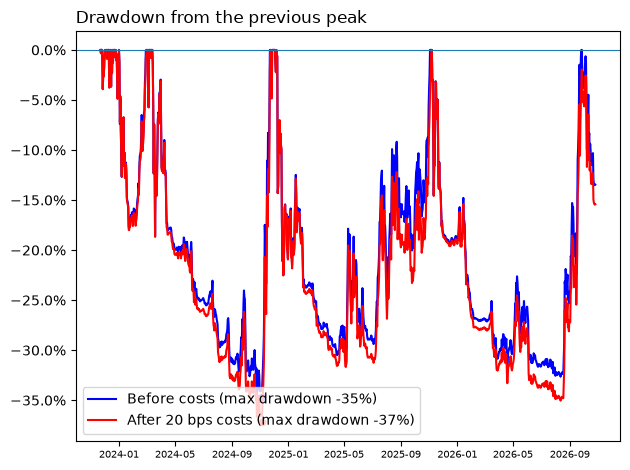

In [25]:
fig, ax = plt.subplots()
for col, color, label in [('before_cost', BLUE, 'Before costs'), ('after_cost', RED, 'After 20 bps costs')]:
    ax.plot(test_mom_dd.index, test_mom_dd[col], color=color, label=f'{label} (max drawdown {test_mom_dd[col].min():.0%})')
    ax.plot(test_mom_dd[col].idxmin(), test_mom_dd[col].min(), 'o', color=color, markersize=7,
            markeredgecolor='white', markeredgewidth=1.5)
ax.axhline(0, linewidth=0.8)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title('Drawdown from the previous peak', loc='left')
ax.legend(loc='lower left')
plt.xticks(fontsize=7)
fig.tight_layout()
plt.show()

## 1b. Unlimited cash (Always buy if close > moving average of close price)

In [26]:
close = data.xs('Close', axis=1, level=1)
close = close.iloc[:-1]
ret = (close / close.shift()) - 1

In [27]:
days = 50
ma = compute_moving_average(close, days)
ma = ma[days-1:]
close = close.loc[close.index.isin(ma.index)]
ret = ret.loc[ret.index.isin(ma.index)]

In [28]:
mom_port = (close > ma)*1
mom_port = mom_port.div(mom_port.abs().sum(axis=1),0)

### Performance Calculation

In [29]:
mom_ret = (mom_port.shift()*ret).sum(axis=1)

In [30]:
mom_trans_cost = np.sum(abs(mom_port.shift(2)-mom_port.shift()).fillna(0), axis=1)*COST_PER_TRANSACTION
mom_trans_cost = mom_trans_cost.dropna()
mom_ret_after_tx_cost = (mom_ret - mom_trans_cost).dropna()

In [31]:
mom_returns = pd.DataFrame({'before_cost': mom_ret, 'after_cost': mom_ret_after_tx_cost})

#### Drawdown

In [32]:
dd = mom_returns.apply(drawdown)

dd_table = pd.DataFrame({
    'max_drawdown': dd.min(),
    'trough_date': dd.idxmin().dt.date,
    'longest_drawdown_days': dd.apply(drawdown_duration).max(),
})

dd_table

,max_drawdown,trough_date,longest_drawdown_days
before_cost,-1.043399,2026-06-24,445
after_cost,-1.194091,2026-06-24,820


In [33]:
mom_dd = mom_returns.apply(drawdown)
mom_dd_table = pd.DataFrame({
    'max_drawdown': mom_dd.min(),
    'trough_date': mom_dd.idxmin().dt.date,
    'longest_drawdown_days': mom_dd.apply(drawdown_duration).max(),
})

mom_dd_table

,max_drawdown,trough_date,longest_drawdown_days
before_cost,-1.043399,2026-06-24,445
after_cost,-1.194091,2026-06-24,820


### Charts

#### Daily returns

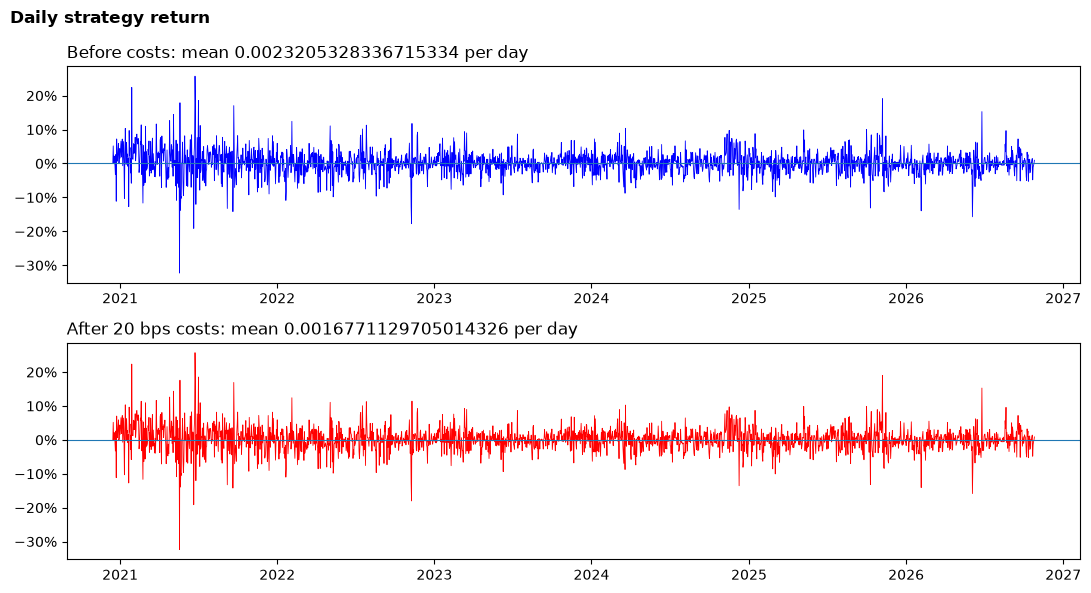

In [34]:
BLUE = 'b'
RED = 'r'

fig, axes = plt.subplots(2, 1, figsize=(11, 6))
for ax, col, color, label in [(axes[0], 'before_cost', BLUE, 'Before costs'),
                              (axes[1], 'after_cost', RED, 'After 20 bps costs')]:
    ax.plot(mom_returns.index, mom_returns[col], color=color, linewidth=0.6)
    ax.axhline(0, linewidth=0.8)
    ax.set_title(f'{label}: mean {mom_returns[col].mean()} per day', loc='left')
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
fig.suptitle('Daily strategy return', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
plt.show()

#### Cumulative return

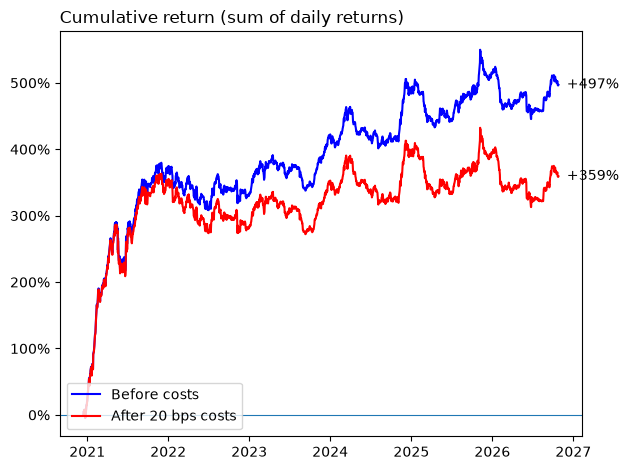

In [35]:
cum = mom_returns.cumsum()
fig, ax = plt.subplots()
ax.plot(cum.index, cum['before_cost'], color=BLUE, label='Before costs')
ax.plot(cum.index, cum['after_cost'], color=RED, label='After 20 bps costs')
ax.axhline(0, linewidth=0.8)
for col, color in [('before_cost', BLUE), ('after_cost', RED)]:
    ax.annotate(f'{cum[col].iloc[-1]:+.0%}', (cum.index[-1], cum[col].iloc[-1]),
                xytext=(6, 0), textcoords='offset points', va='center', fontsize=10)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title('Cumulative return (sum of daily returns)', loc='left')
ax.legend(loc='lower left')
fig.tight_layout()
plt.show()

#### Drawdown, before and after costs

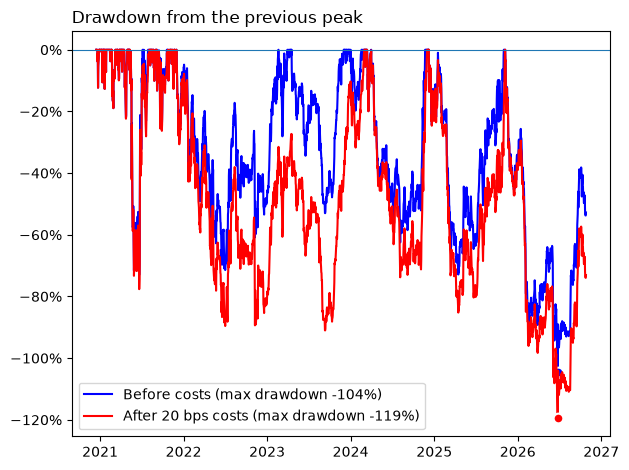

In [36]:
fig, ax = plt.subplots()
for col, color, label in [('before_cost', BLUE, 'Before costs'), ('after_cost', RED, 'After 20 bps costs')]:
    ax.plot(mom_dd.index, mom_dd[col], color=color, label=f'{label} (max drawdown {mom_dd[col].min():.0%})')
    ax.plot(mom_dd[col].idxmin(), mom_dd[col].min(), 'o', color=color, markersize=7,
            markeredgecolor='white', markeredgewidth=1.5)
ax.axhline(0, linewidth=0.8)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title('Drawdown from the previous peak', loc='left')
ax.legend(loc='lower left')
fig.tight_layout()
plt.show()

# 2. XS (Cross Sectional) for Crypto

## Rank

In [37]:
list_column = np.unique(np.array(list(data))[:,0])

close = data.xs('Close', axis=1, level=1)
close = close.iloc[:-1]

In [38]:
ret = close / close.shift() - 1

## Rank Demean

In [39]:
negate = ret*-1
ranked = negate.rank(axis=1)
demeaned = ranked.subtract(ranked.mean(axis=1), axis=0)
port = demeaned.divide(demeaned.abs().sum(axis=1), axis=0)

port_ret = (port.shift()*ret).sum(axis=1, min_count=1)

### Based on the first try, there is an anomaly in DEL

In [40]:
data['DEL-USD'].loc[['2026-07-09','2026-07-10','2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14']]

Price,Open,High,Low,Close,Volume
Date,,,,,
2026-07-09,0.000986,0.000986,0.000986,0.000986,246101.0
2026-07-10,0.000986,0.000986,0.000986,0.000986,246101.0
2026-07-11,0.000986,0.000986,0.000986,0.000986,246101.0
2026-07-12,0.000986,1.037115,0.000986,0.985960,334145.0
2026-07-13,0.985960,0.987519,0.795527,0.912111,341684.0
2026-07-14,0.912111,0.914125,0.794774,0.861204,336773.0


In [41]:
data = data.drop('DEL-USD', axis=1, level=0)

In [42]:
list_column = np.unique(np.array(list(data))[:,0])

close = data.xs('Close', axis=1, level=1)
close = close.iloc[:-1]
ret = close / close.shift() - 1

negate = ret*-1
ranked = negate.rank(1)
demeaned = ranked.subtract(ranked.mean(axis=1), axis=0)
port = demeaned.divide(demeaned.abs().sum(axis=1), axis=0)

In [43]:
port_ret = (port.shift()*ret)

### Performance Calculation

#### Return, Volatility, and Sharpe Ratio

In [44]:
import math

In [45]:
# total_sharpe = port_ret.sum(axis=1).mean()/port_ret.sum(axis=1).std()*math.sqrt(252)
total_sharpe = calculate_performance(port_ret)

In [46]:
daily_ret = port_ret.sum(axis=1, min_count=1)
daily_ret = daily_ret.dropna()
sharpe = lambda x: x.mean()/x.std()*math.sqrt(252)
daily_ret.groupby([x.year for x in daily_ret.index]).apply(sharpe)

2020   -1.359371
2021   -1.597750
2022    0.535393
2023   -0.459380
2024   -0.457762
2025   -1.634537
2026   -1.346052
dtype: float64

In [47]:
COST_PER_TRANSACTION = 20/10000
trans_cost = np.sum(abs(port.shift(2)-port.shift()).fillna(0), axis=1)*COST_PER_TRANSACTION
trans_cost = trans_cost.dropna()
port_ret_after_tx_cost = port_ret - trans_cost

In [48]:
daily_ret_after_tx_cost = (daily_ret - trans_cost).dropna()

In [49]:
returns = pd.DataFrame({'before_cost': daily_ret, 'after_cost': daily_ret_after_tx_cost}).dropna()

#### Drawdown

In [50]:
dd = returns.apply(drawdown)

dd_table = pd.DataFrame({
    'max_drawdown': dd.min(),
    'trough_date': dd.idxmin().dt.date,
    'longest_drawdown_days': dd.apply(drawdown_duration).max(),
})

dd_table

,max_drawdown,trough_date,longest_drawdown_days
before_cost,-1.637126,2026-09-27,2173
after_cost,-7.266467,2026-10-11,2181


### Charts

#### Daily returns

In [51]:
import matplotlib.pyplot as plt

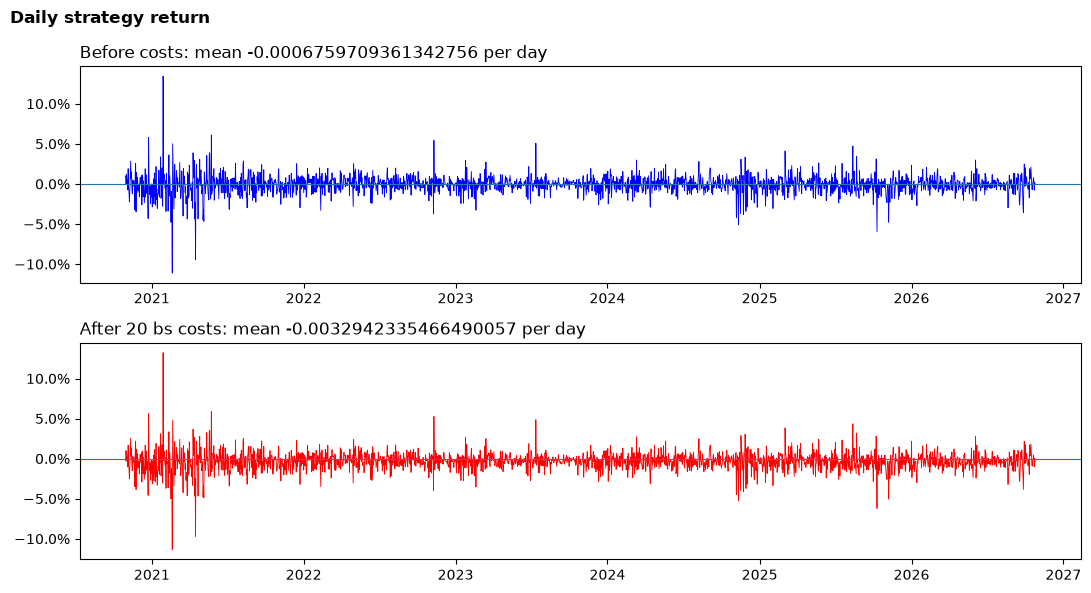

In [52]:
BLUE = 'b'
RED = 'r'

fig, axes = plt.subplots(2, 1, figsize=(11, 6))
for ax, col, color, label in [(axes[0], 'before_cost', BLUE, 'Before costs'),
                              (axes[1], 'after_cost', RED, 'After 20 bs costs')]:
    ax.plot(returns.index, returns[col], color=color, linewidth=0.6)
    ax.axhline(0, linewidth=0.8)
    ax.set_title(f'{label}: mean {returns[col].mean()} per day', loc='left')
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
fig.suptitle('Daily strategy return', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
plt.show()

#### Cumulative return

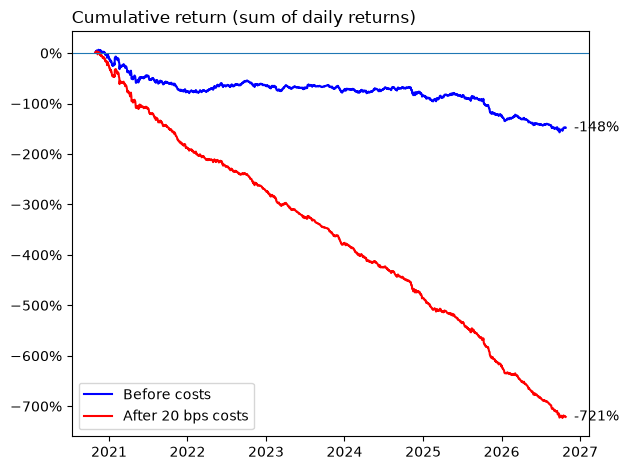

In [53]:
cum = returns.cumsum()
fig, ax = plt.subplots()
ax.plot(cum.index, cum['before_cost'], color=BLUE, label='Before costs')
ax.plot(cum.index, cum['after_cost'], color=RED, label='After 20 bps costs')
ax.axhline(0, linewidth=0.8)
for col, color in [('before_cost', BLUE), ('after_cost', RED)]:
    ax.annotate(f'{cum[col].iloc[-1]:+.0%}', (cum.index[-1], cum[col].iloc[-1]),
                xytext=(6, 0), textcoords='offset points', va='center', fontsize=10)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title('Cumulative return (sum of daily returns)', loc='left')
ax.legend(loc='lower left')
fig.tight_layout()
plt.show()

#### Drawdown, before and after costs

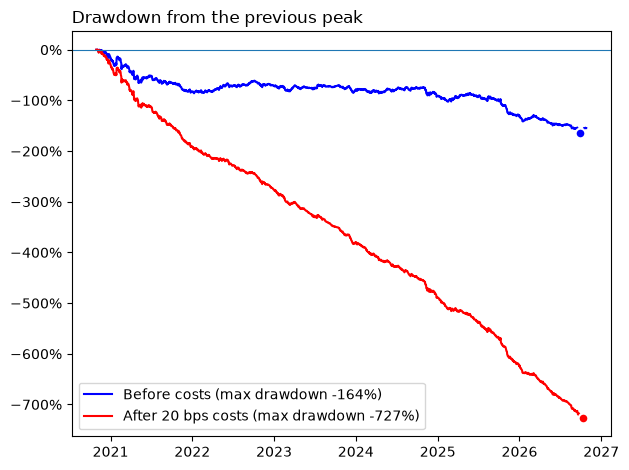

In [54]:
fig, ax = plt.subplots()
for col, color, label in [('before_cost', BLUE, 'Before costs'), ('after_cost', RED, 'After 20 bps costs')]:
    ax.plot(dd.index, dd[col], color=color, label=f'{label} (max drawdown {dd[col].min():.0%})')
    ax.plot(dd[col].idxmin(), dd[col].min(), 'o', color=color, markersize=7,
            markeredgecolor='white', markeredgewidth=1.5)
ax.axhline(0, linewidth=0.8)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title('Drawdown from the previous peak', loc='left')
ax.legend(loc='lower left')
fig.tight_layout()
plt.show()